# 📩 Probabilistic SMS Spam Detection

**Course:** BAMAT207 – Probability and Statistics  
**Topic:** Probability and Random Variables  
**Student:** Srivathsan Kuppusamy Saravanan  |  **Reg. No.:** 25BCE2363  
**Dataset:** SMS Spam Collection (UCI Machine Learning Repository, 5,574 labelled messages)

---

### Objective
Build a Python system that classifies an incoming SMS as **Spam** or **Genuine (Ham)**, using concepts from probability:
conditional probability, Bayes' theorem, random variables, expectation and variance, followed by a **Multinomial Naive Bayes** classifier that outputs prediction probabilities.

### Notebook roadmap
| Step | Section |
|---|---|
| 1 | Dataset handling |
| 2 | Dataset analysis (class probabilities and chart) |
| 3 | Word-based probability analysis with Bayes' theorem |
| 4 | Random variable analysis: E(Y) and Var(Y) |
| 5 | Data preparation (80/20 stratified split + CountVectorizer) |
| 6 | Model building (Multinomial Naive Bayes) |
| 7 | Model evaluation |
| 8 | Real-time testing |
| 9 | Save outputs and final summary |

## 0. Setup: install and import libraries

In [1]:
# ucimlrepo is not pre-installed in Google Colab; this installs it quietly.
%pip install -q ucimlrepo

In [2]:
import re
import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

import joblib

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42  # fixed seed so results are reproducible

print("All libraries imported successfully.")

All libraries imported successfully.


## 1. Dataset Handling

Tasks: load the messages and labels, check missing values, remove duplicate messages, and convert labels to numbers (**Spam = 1, Ham = 0**).

The dataset is downloaded directly from UCI using `ucimlrepo`. If that service is unreachable, the code automatically falls back to downloading the official zip file from UCI.

In [3]:
def _decode(raw_bytes):
    """Decode bytes as UTF-8, falling back to Latin-1 if needed."""
    try:
        return raw_bytes.decode("utf-8")
    except UnicodeDecodeError:
        return raw_bytes.decode("latin-1")


def load_sms_dataset():
    """Return a DataFrame with columns ['label', 'message']."""
    # Option 1: ucimlrepo (UCI dataset id 228 = SMS Spam Collection)
    try:
        from ucimlrepo import fetch_ucirepo
        repo = fetch_ucirepo(id=228)
        features = repo.data.features
        targets = repo.data.targets
        data = pd.DataFrame({
            "label": targets.iloc[:, 0].values,
            "message": features.iloc[:, 0].values,
        })
        print("Dataset loaded using ucimlrepo.")
        return data
    except Exception as err:
        print(f"ucimlrepo failed ({type(err).__name__}: {err}). Trying direct download...")

    # Option 2: direct download of the official zip file from UCI
    url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
    with urllib.request.urlopen(url, timeout=60) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    text = _decode(archive.read("SMSSpamCollection"))
    data = pd.read_csv(io.StringIO(text), sep="\t", header=None,
                       names=["label", "message"], quoting=3)
    print("Dataset loaded from the UCI zip file.")
    return data


df = load_sms_dataset()
print("Raw shape:", df.shape)
df.head()

ucimlrepo failed (DatasetNotFoundError: "SMS Spam Collection" dataset (id=228) exists in the repository, but is not available for import. Please select a dataset from this list: https://archive.ics.uci.edu/datasets?skip=0&take=10&sort=desc&orderBy=NumHits&search=&Python=true). Trying direct download...
Dataset loaded from the UCI zip file.
Raw shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [4]:
# --- Basic structure and missing values ---
print("Raw dataset shape (rows, columns):", df.shape)
print()
df.info()

print("\nMissing values per column (before cleaning):")
print(df.isnull().sum())

Raw dataset shape (rows, columns): (5574, 2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5574 non-null   object
 1   message  5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values per column (before cleaning):
label      0
message    0
dtype: int64


In [5]:
# --- Cleaning ---
raw_count = len(df)

# 1) Normalise the label text ('Spam', ' ham ' -> 'spam', 'ham')
df["label"] = df["label"].astype(str).str.strip().str.lower()

# 2) Remove rows with missing/empty messages
df = df.dropna(subset=["label", "message"])
df["message"] = df["message"].astype(str).str.strip()
df = df[df["message"] != ""]
after_missing = len(df)

# 3) Remove duplicate messages (keep the first occurrence)
duplicates_found = int(df.duplicated(subset="message").sum())
df = df.drop_duplicates(subset="message", keep="first").reset_index(drop=True)
after_duplicates = len(df)

# 4) Check that only the two expected labels remain
assert set(df["label"].unique()) <= {"spam", "ham"}, f"Unexpected labels: {df['label'].unique()}"

# 5) Convert labels to numbers: Spam = 1, Ham = 0
df["label_num"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)

print(f"Messages in raw dataset          : {raw_count}")
print(f"Rows removed (missing/empty)     : {raw_count - after_missing}")
print(f"Duplicate messages removed       : {duplicates_found}")
print(f"Messages after cleaning          : {after_duplicates}")
print("\nMissing values after cleaning:")
print(df.isnull().sum())
df.head()

Messages in raw dataset          : 5574
Rows removed (missing/empty)     : 0
Duplicate messages removed       : 414
Messages after cleaning          : 5160

Missing values after cleaning:
label        0
message      0
label_num    0
dtype: int64


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


In [6]:
# --- Text cleaning with regular expressions (re) ---
def clean_text(text):
    """Lower-case, replace URLs with a token, strip punctuation, collapse spaces."""
    text = str(text).lower()
    text = re.sub(r"(https?://\S+|www\.\S+)", " url ", text)   # web links -> 'url'
    text = re.sub(r"[^a-z0-9\s]", " ", text)                     # remove punctuation/symbols
    text = re.sub(r"\s+", " ", text).strip()                     # collapse whitespace
    return text


df["clean_message"] = df["message"].apply(clean_text)

# Cleaned dataset summary (one of the required deliverables)
summary = pd.DataFrame({
    "Metric": [
        "Messages in raw dataset",
        "Duplicate messages removed",
        "Messages after cleaning",
        "Spam messages",
        "Ham messages",
        "Average message length (characters)",
        "Average message length (words)",
    ],
    "Value": [
        raw_count,
        duplicates_found,
        len(df),
        int((df["label_num"] == 1).sum()),
        int((df["label_num"] == 0).sum()),
        round(df["message"].str.len().mean(), 2),
        round(df["clean_message"].str.split().str.len().mean(), 2),
    ],
})
print("CLEANED DATASET SUMMARY")
summary

CLEANED DATASET SUMMARY


,Metric,Value
0,Messages in raw dataset,5574.00
1,Duplicate messages removed,414.00
2,Messages after cleaning,5160.00
3,Spam messages,642.00
4,Ham messages,4518.00
5,Average message length (characters),79.14
6,Average message length (words),15.93


## 2. Dataset Analysis

Class probabilities, using relative frequency:

$$P(\text{Spam}) = \frac{\text{Number of spam messages}}{\text{Total messages}} \qquad P(\text{Ham}) = \frac{\text{Number of ham messages}}{\text{Total messages}}$$

In [7]:
total_messages = len(df)
n_spam = int((df["label_num"] == 1).sum())
n_ham = int((df["label_num"] == 0).sum())

p_spam = n_spam / total_messages
p_ham = n_ham / total_messages

print(f"Total messages : {total_messages}")
print(f"Spam messages  : {n_spam}")
print(f"Ham messages   : {n_ham}")
print()
print(f"P(Spam) = {n_spam} / {total_messages} = {p_spam:.4f}")
print(f"P(Ham)  = {n_ham} / {total_messages} = {p_ham:.4f}")
print(f"P(Spam) + P(Ham) = {p_spam + p_ham:.4f}")

Total messages : 5160
Spam messages  : 642
Ham messages   : 4518

P(Spam) = 642 / 5160 = 0.1244
P(Ham)  = 4518 / 5160 = 0.8756
P(Spam) + P(Ham) = 1.0000


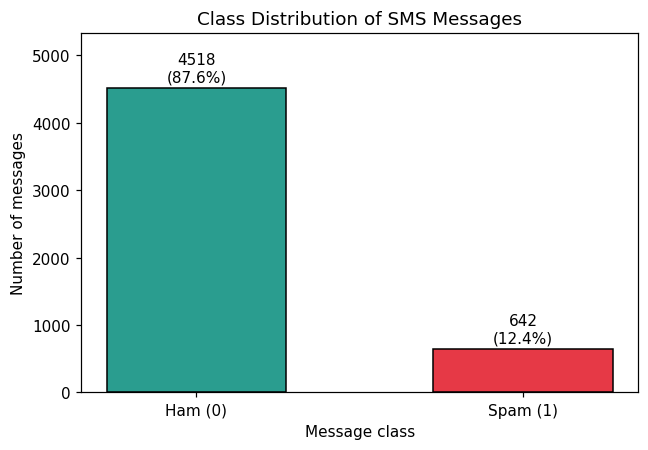

In [8]:
# --- Class-distribution bar chart ---
counts = [n_ham, n_spam]
labels = ["Ham (0)", "Spam (1)"]
colors = ["#2a9d8f", "#e63946"]

fig, ax = plt.subplots(figsize=(6, 4.2))
bars = ax.bar(labels, counts, color=colors, edgecolor="black", width=0.55)

for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + total_messages * 0.01,
            f"{count}\n({count / total_messages:.1%})", ha="center", va="bottom", fontsize=10)

ax.set_title("Class Distribution of SMS Messages")
ax.set_xlabel("Message class")
ax.set_ylabel("Number of messages")
ax.set_ylim(0, max(counts) * 1.18)
plt.tight_layout()
plt.show()

## 3. Word-Based Probability Analysis

For each suspicious word `w` in **free, prize, win, urgent, offer**:

**Direct (frequency) method**

$$P(\text{Spam} \mid w) = \frac{\text{Number of spam messages containing } w}{\text{Total messages containing } w}$$

**Bayes' theorem (verification)**

$$P(\text{Spam} \mid w) = \frac{P(w \mid \text{Spam}) \times P(\text{Spam})}{P(w)}$$

where $P(w \mid \text{Spam})$ = spam messages containing $w$ / all spam messages, and $P(w)$ = messages containing $w$ / all messages.

*A message "contains" a word only when the word appears as a whole word (for example, "win" does not match "winner" or "window").*

In [9]:
suspicious_words = ["free", "prize", "win", "urgent", "offer"]
is_spam = df["label_num"] == 1

rows = []
for word in suspicious_words:
    pattern = rf"\b{re.escape(word)}\b"
    contains = df["clean_message"].str.contains(pattern, regex=True)

    n_with_word = int(contains.sum())                    # messages containing the word
    n_spam_with_word = int((contains & is_spam).sum())   # spam messages containing the word

    if n_with_word == 0:
        rows.append({"Word": word, "Msgs with word": 0, "Spam with word": 0,
                     "P(Spam|word) direct": np.nan, "P(word|Spam)": np.nan,
                     "P(word)": np.nan, "P(Spam|word) Bayes": np.nan, "Match": "n/a"})
        continue

    # Direct method
    p_spam_given_word = n_spam_with_word / n_with_word

    # Bayes' theorem
    p_word_given_spam = n_spam_with_word / n_spam
    p_word = n_with_word / total_messages
    p_bayes = (p_word_given_spam * p_spam) / p_word

    rows.append({
        "Word": word,
        "Msgs with word": n_with_word,
        "Spam with word": n_spam_with_word,
        "P(Spam|word) direct": round(p_spam_given_word, 4),
        "P(word|Spam)": round(p_word_given_spam, 4),
        "P(word)": round(p_word, 4),
        "P(Spam|word) Bayes": round(p_bayes, 4),
        "Match": "Yes" if np.isclose(p_spam_given_word, p_bayes) else "NO",
    })

word_table = pd.DataFrame(rows)
print(f"Baseline P(Spam) = {p_spam:.4f}\n")
word_table

Baseline P(Spam) = 0.1244



,Word,Msgs with word,Spam with word,P(Spam|word) direct,P(word|Spam),P(word),P(Spam|word) Bayes,Match
0,free,199,144,0.7236,0.2243,0.0386,0.7236,Yes
1,prize,70,70,1.0000,0.1090,0.0136,1.0000,Yes
2,win,53,47,0.8868,0.0732,0.0103,0.8868,Yes
3,urgent,61,56,0.9180,0.0872,0.0118,0.9180,Yes
4,offer,30,24,0.8000,0.0374,0.0058,0.8000,Yes


In [10]:
# --- Detailed worked calculation for P(Spam | free) ---
word = "free"
contains = df["clean_message"].str.contains(rf"\b{word}\b", regex=True)
n_w = int(contains.sum())
n_sw = int((contains & is_spam).sum())

p_w_given_spam = n_sw / n_spam
p_w = n_w / total_messages
direct = n_sw / n_w
bayes = p_w_given_spam * p_spam / p_w

print("Worked example: P(Spam | 'free')")
print("-" * 55)
print(f"Spam messages containing 'free' : {n_sw}")
print(f"All messages containing 'free'  : {n_w}")
print(f"Direct   : {n_sw} / {n_w} = {direct:.4f}")
print()
print(f"P(free | Spam) = {n_sw} / {n_spam} = {p_w_given_spam:.4f}")
print(f"P(Spam)        = {p_spam:.4f}")
print(f"P(free)        = {n_w} / {total_messages} = {p_w:.4f}")
print(f"Bayes    : ({p_w_given_spam:.4f} x {p_spam:.4f}) / {p_w:.4f} = {bayes:.4f}")
print()
print("Both methods agree:", np.isclose(direct, bayes))

Worked example: P(Spam | 'free')
-------------------------------------------------------
Spam messages containing 'free' : 144
All messages containing 'free'  : 199
Direct   : 144 / 199 = 0.7236

P(free | Spam) = 144 / 642 = 0.2243
P(Spam)        = 0.1244
P(free)        = 199 / 5160 = 0.0386
Bayes    : (0.2243 x 0.1244) / 0.0386 = 0.7236

Both methods agree: True


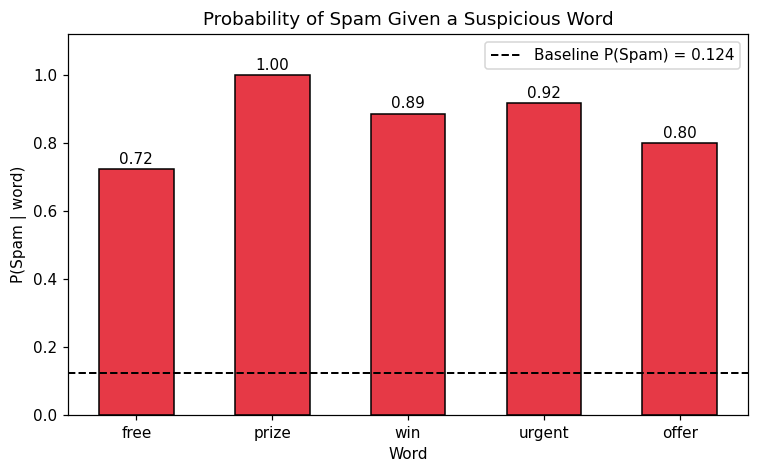

In [11]:
# --- Chart: P(Spam | word) compared with the baseline P(Spam) ---
valid = word_table.dropna(subset=["P(Spam|word) direct"])

fig, ax = plt.subplots(figsize=(7, 4.4))
bars = ax.bar(valid["Word"], valid["P(Spam|word) direct"], color="#e63946", edgecolor="black", width=0.55)
ax.axhline(p_spam, color="black", linestyle="--", linewidth=1.3, label=f"Baseline P(Spam) = {p_spam:.3f}")

for bar, value in zip(bars, valid["P(Spam|word) direct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.015, f"{value:.2f}", ha="center", fontsize=10)

ax.set_title("Probability of Spam Given a Suspicious Word")
ax.set_xlabel("Word")
ax.set_ylabel("P(Spam | word)")
ax.set_ylim(0, 1.12)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Random Variable Analysis

Define the discrete random variable

$$Y = \begin{cases} 1 & \text{if the message is spam} \\ 0 & \text{if the message is ham} \end{cases}$$

Y follows a **Bernoulli distribution** with parameter $p = P(\text{Spam})$:

$$E(Y) = p \qquad \text{Var}(Y) = p(1 - p)$$

In [12]:
Y = df["label_num"].to_numpy()

p = p_spam
expectation = p                 # E(Y) = p
variance = p * (1 - p)          # Var(Y) = p(1 - p)
std_dev = np.sqrt(variance)

print(f"p = P(Spam)            = {p:.4f}")
print(f"E(Y)   = p             = {expectation:.4f}")
print(f"Var(Y) = p x (1 - p)   = {variance:.4f}")
print(f"Std. deviation of Y    = {std_dev:.4f}")

# Cross-check using numpy directly on the data (population mean / variance)
print()
print(f"Verification with numpy -> mean(Y) = {np.mean(Y):.4f}, var(Y) = {np.var(Y):.4f}")
print("E(Y) matches  :", np.isclose(np.mean(Y), expectation))
print("Var(Y) matches:", np.isclose(np.var(Y), variance))

p = P(Spam)            = 0.1244
E(Y)   = p             = 0.1244
Var(Y) = p x (1 - p)   = 0.1089
Std. deviation of Y    = 0.3301

Verification with numpy -> mean(Y) = 0.1244, var(Y) = 0.1089
E(Y) matches  : True
Var(Y) matches: True


## 5. Data Preparation

* **80%** of the messages for training and **20%** for testing
* **Stratified sampling** so that the spam-to-ham proportion is the same in both sets
* **CountVectorizer** converts each message into a vector of word counts

The vectorizer is **fitted on the training data only**, then used to transform the test data. This prevents information from the test set leaking into training.

In [13]:
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,                 # keeps the spam/ham proportion identical in both sets
    random_state=RANDOM_STATE,
)

print(f"Training messages: {len(X_train)}  |  Testing messages: {len(X_test)}")
print(f"Spam proportion -> full: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")

# Convert text to word-count features
vectorizer = CountVectorizer()
X_train_counts = vectorizer.fit_transform(X_train)   # learn vocabulary from TRAIN only
X_test_counts = vectorizer.transform(X_test)         # reuse the same vocabulary for TEST

print()
print("Training feature matrix shape:", X_train_counts.shape, "(messages x vocabulary words)")
print("Testing feature matrix shape :", X_test_counts.shape)

Training messages: 4128  |  Testing messages: 1032
Spam proportion -> full: 0.1244 | train: 0.1245 | test: 0.1240

Training feature matrix shape: (4128, 7620) (messages x vocabulary words)
Testing feature matrix shape : (1032, 7620)


## 6. Model Building

A **Multinomial Naive Bayes** classifier is trained on the word-count features. It is well suited to discrete count data such as text, and it applies Bayes' theorem under the "naive" assumption that words are conditionally independent given the class:

$$P(\text{Spam} \mid \text{message}) \propto P(\text{Spam}) \prod_i P(w_i \mid \text{Spam})$$

In [14]:
model = MultinomialNB()
model.fit(X_train_counts, y_train)

print("Model trained:", model)
print("Classes learned (0 = Ham, 1 = Spam):", model.classes_)
print("Learned class priors  P(Ham), P(Spam):", np.round(np.exp(model.class_log_prior_), 4))

Model trained: MultinomialNB()
Classes learned (0 = Ham, 1 = Spam): [0 1]
Learned class priors  P(Ham), P(Spam): [0.8755 0.1245]


In [15]:
# --- Bonus: words that most strongly indicate spam / ham ---
vocab = np.array(vectorizer.get_feature_names_out())
log_ratio = model.feature_log_prob_[1] - model.feature_log_prob_[0]   # log P(w|Spam) - log P(w|Ham)

top_spam = vocab[np.argsort(log_ratio)[::-1][:10]]
top_ham = vocab[np.argsort(log_ratio)[:10]]

print("Top 10 words most indicative of SPAM:", ", ".join(top_spam))
print("Top 10 words most indicative of HAM :", ", ".join(top_ham))

Top 10 words most indicative of SPAM: claim, prize, nokia, 150p, tone, guaranteed, 18, cs, 1000, 500
Top 10 words most indicative of HAM : gt, lt, he, lor, da, she, later, really, but, doing


## 7. Model Evaluation

Metrics: **accuracy, precision, recall, F1-score, confusion matrix**.  
Spam is the *positive* class (1). Precision, recall and F1 below are reported for the spam class.

| Term | Meaning |
|---|---|
| TP | spam correctly detected as spam |
| TN | ham correctly detected as ham |
| FP | **ham wrongly classified as spam** (a genuine message is blocked) |
| FN | **spam wrongly classified as ham** (a spam message gets through) |

In [16]:
y_pred = model.predict(X_test_counts)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

print("MODEL PERFORMANCE ON THE TEST SET (spam = positive class)")
print("-" * 55)
print(f"Accuracy  : {accuracy:.4f}  ({accuracy:.2%})")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nDETAILED CLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"], digits=4, zero_division=0))

MODEL PERFORMANCE ON THE TEST SET (spam = positive class)
-------------------------------------------------------
Accuracy  : 0.9826  (98.26%)
Precision : 0.9508
Recall    : 0.9062
F1-score  : 0.9280

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham     0.9868    0.9934    0.9901       904
        Spam     0.9508    0.9062    0.9280       128

    accuracy                         0.9826      1032
   macro avg     0.9688    0.9498    0.9590      1032
weighted avg     0.9823    0.9826    0.9824      1032



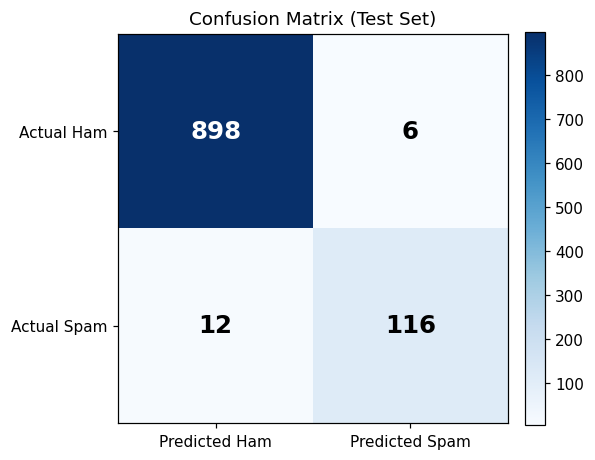

True Negatives  (ham -> ham)    : 898
False Positives (ham -> SPAM)   : 6   <- genuine messages incorrectly classified as spam
False Negatives (spam -> HAM)   : 12   <- spam messages incorrectly classified as genuine
True Positives  (spam -> spam)  : 116


In [17]:
# --- Confusion matrix ---
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted Ham", "Predicted Spam"])
ax.set_yticklabels(["Actual Ham", "Actual Spam"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16, fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

ax.set_title("Confusion Matrix (Test Set)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

print(f"True Negatives  (ham -> ham)    : {tn}")
print(f"False Positives (ham -> SPAM)   : {fp}   <- genuine messages incorrectly classified as spam")
print(f"False Negatives (spam -> HAM)   : {fn}   <- spam messages incorrectly classified as genuine")
print(f"True Positives  (spam -> spam)  : {tp}")

In [18]:
# --- Inspect the actual misclassified messages ---
results = pd.DataFrame({
    "message": df.loc[X_test.index, "message"],
    "actual": y_test.map({0: "Ham", 1: "Spam"}),
    "predicted": pd.Series(y_pred, index=X_test.index).map({0: "Ham", 1: "Spam"}),
})

spam_as_ham = results[(results["actual"] == "Spam") & (results["predicted"] == "Ham")]
ham_as_spam = results[(results["actual"] == "Ham") & (results["predicted"] == "Spam")]

print(f"Spam messages incorrectly classified as genuine (Ham): {len(spam_as_ham)}")
display(spam_as_ham.head(5))

print(f"\nGenuine messages incorrectly classified as Spam: {len(ham_as_spam)}")
display(ham_as_spam.head(5))

Spam messages incorrectly classified as genuine (Ham): 12


,message,actual,predicted
1450,"SMS. ac JSco: Energy is high, but u may not know where 2channel it. 2day ur leadership skills r strong. Psychic? Rep...",Spam,Ham
3173,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,Spam,Ham
2967,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better...",Spam,Ham
671,Hi I'm sue. I am 20 years old and work as a lapdancer. I love sex. Text me live - I'm i my bedroom now. text SUE to ...,Spam,Ham
2299,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,Spam,Ham



Genuine messages incorrectly classified as Spam: 6


,message,actual,predicted
4410,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,Ham,Spam
4531,Nokia phone is lovly..,Ham,Spam
4293,Have you laid your airtel line to rest?,Ham,Spam
3655,Unlimited texts. Limited minutes.,Ham,Spam
2819,"Mostly sports type..lyk footbl,crckt..",Ham,Spam


**Interpretation:** a false positive (ham flagged as spam) can hide an important message from the user, while a false negative (spam marked as ham) lets unwanted or fraudulent content through. Precision tells us how trustworthy a "spam" prediction is, and recall tells us how much of the real spam is caught.

## 8. Real-Time Testing

The function `predict_sms()` takes a new message, applies the same cleaning and vectorizer used in training, and prints the prediction with both class probabilities.

In [19]:
def predict_sms(message, verbose=True):
    """Classify one SMS and return (label, P(Spam|message), P(Ham|message))."""
    cleaned = clean_text(message)
    features = vectorizer.transform([cleaned])
    probabilities = model.predict_proba(features)[0]

    classes = list(model.classes_)
    p_spam_msg = probabilities[classes.index(1)]
    p_ham_msg = probabilities[classes.index(0)]
    label = "Spam" if p_spam_msg >= 0.5 else "Ham"

    if verbose:
        print(f"Message: {message}")
        print(f"Prediction: {label}")
        print(f"P(Spam | Message) = {p_spam_msg:.2f}")
        print(f"P(Ham | Message) = {p_ham_msg:.2f}")
    return label, p_spam_msg, p_ham_msg


# Example from the project brief
predict_sms("Congratulations! You have won a free prize. Claim now.")

Message: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 1.00
P(Ham | Message) = 0.00


('Spam', np.float64(0.9999998224155691), np.float64(1.7758443303515845e-07))

In [20]:
# More sample messages
samples = [
    "URGENT! You have won a 1 week FREE membership in our 100,000 prize jackpot! Txt the word CLAIM to 81010",
    "Hey, are we still meeting for lunch at 1 pm today?",
    "WINNER!! As a valued network customer you have been selected to receive a 900 prize reward. Call 09061701461 now.",
    "Can you send me the notes from yesterday's class? Thanks!",
    "Free entry in a weekly competition to win FA Cup tickets. Text FA to 87121 to receive entry question.",
]

for sms in samples:
    predict_sms(sms)
    print("-" * 60)

Message: URGENT! You have won a 1 week FREE membership in our 100,000 prize jackpot! Txt the word CLAIM to 81010
Prediction: Spam
P(Spam | Message) = 1.00
P(Ham | Message) = 0.00
------------------------------------------------------------
Message: Hey, are we still meeting for lunch at 1 pm today?
Prediction: Ham
P(Spam | Message) = 0.00
P(Ham | Message) = 1.00
------------------------------------------------------------
Message: WINNER!! As a valued network customer you have been selected to receive a 900 prize reward. Call 09061701461 now.
Prediction: Spam
P(Spam | Message) = 1.00
P(Ham | Message) = 0.00
------------------------------------------------------------
Message: Can you send me the notes from yesterday's class? Thanks!
Prediction: Ham
P(Spam | Message) = 0.00
P(Ham | Message) = 1.00
------------------------------------------------------------
Message: Free entry in a weekly competition to win FA Cup tickets. Text FA to 87121 to receive entry question.
Prediction: Spam
P(S

### Try your own message
Run the cell below and type any SMS when prompted. Press **Enter on an empty line** (or type `quit`) to stop.  
If you use *Run all*, set `INTERACTIVE = False` to skip the prompt.

In [21]:
INTERACTIVE = True   # set to False to skip the input prompt (e.g. when using "Run all")

if INTERACTIVE:
    while True:
        user_message = input("Enter an SMS message (empty line or 'quit' to stop): ")
        if user_message.strip().lower() in {"", "quit", "exit", "q"}:
            print("Stopped.")
            break
        predict_sms(user_message)
        print("-" * 60)

Enter an SMS message (empty line or 'quit' to stop): Congratulations! You have won a free prize. Claim now.
Message: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 1.00
P(Ham | Message) = 0.00
------------------------------------------------------------
Enter an SMS message (empty line or 'quit' to stop): Are we meeting at 5 pm today?
Message: Are we meeting at 5 pm today?
Prediction: Ham
P(Spam | Message) = 0.00
P(Ham | Message) = 1.00
------------------------------------------------------------
Enter an SMS message (empty line or 'quit' to stop): quit
Stopped.


## 9. Save Outputs and Final Summary

The cleaned dataset, the trained model and the vectorizer are saved so they can be uploaded to GitHub or reused later.

In [22]:
df[["label", "label_num", "message", "clean_message"]].to_csv("sms_spam_cleaned.csv", index=False)
joblib.dump(model, "spam_naive_bayes_model.joblib")
joblib.dump(vectorizer, "spam_count_vectorizer.joblib")

print("Saved files:")
print(" - sms_spam_cleaned.csv")
print(" - spam_naive_bayes_model.joblib")
print(" - spam_count_vectorizer.joblib")
print()
print("To reload later:")
print("   model = joblib.load('spam_naive_bayes_model.joblib')")
print("   vectorizer = joblib.load('spam_count_vectorizer.joblib')")

Saved files:
 - sms_spam_cleaned.csv
 - spam_naive_bayes_model.joblib
 - spam_count_vectorizer.joblib

To reload later:
   model = joblib.load('spam_naive_bayes_model.joblib')
   vectorizer = joblib.load('spam_count_vectorizer.joblib')


In [23]:
print("=" * 60)
print("                 FINAL PROJECT SUMMARY")
print("=" * 60)
print(f"Messages after cleaning : {total_messages}  (spam: {n_spam}, ham: {n_ham})")
print(f"P(Spam) = {p_spam:.4f}   P(Ham) = {p_ham:.4f}")
print(f"E(Y) = {expectation:.4f}   Var(Y) = {variance:.4f}")
print()
print("Word analysis  P(Spam | word):")
for _, r in word_table.iterrows():
    print(f"   {r['Word']:<7} -> {r['P(Spam|word) direct']}")
print()
print(f"Train / test split      : {len(X_train)} / {len(X_test)} (stratified)")
print(f"Accuracy                : {accuracy:.4f}")
print(f"Precision (spam)        : {precision:.4f}")
print(f"Recall (spam)           : {recall:.4f}")
print(f"F1-score (spam)         : {f1:.4f}")
print(f"Spam classified as ham  : {fn}")
print(f"Ham classified as spam  : {fp}")
print("=" * 60)

                 FINAL PROJECT SUMMARY
Messages after cleaning : 5160  (spam: 642, ham: 4518)
P(Spam) = 0.1244   P(Ham) = 0.8756
E(Y) = 0.1244   Var(Y) = 0.1089

Word analysis  P(Spam | word):
   free    -> 0.7236
   prize   -> 1.0
   win     -> 0.8868
   urgent  -> 0.918
   offer   -> 0.8

Train / test split      : 4128 / 1032 (stratified)
Accuracy                : 0.9826
Precision (spam)        : 0.9508
Recall (spam)           : 0.9062
F1-score (spam)         : 0.9280
Spam classified as ham  : 12
Ham classified as spam  : 6


## Conclusion

* The dataset was cleaned (missing values checked, duplicates removed, labels encoded as Spam = 1 / Ham = 0) and its class probabilities were computed.
* Conditional probabilities such as P(Spam | free) were calculated from frequencies and **verified with Bayes' theorem**; suspicious words raise the probability of spam far above the baseline P(Spam).
* The spam indicator Y is a Bernoulli random variable with E(Y) = p and Var(Y) = p(1 − p).
* A Multinomial Naive Bayes model on CountVectorizer features, trained on a stratified 80/20 split, classifies new SMS messages and reports P(Spam | Message) and P(Ham | Message).
* Together these steps show how conditional probability, Bayes' theorem, expectation and variance support a basic AI classification system.